# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 79987, Pedro Pequeno, pl.pequeno@campus.fct.unl.pt
- 68614, Rodrigo Sinde, r.sinde@campus.fct.unl.pt

## 1. Introduction

An edited video is a sequence of shots separated by cuts, and editors often go back to a scene shown earlier. In this project we (1) find the cuts, (2) avoid false cuts caused by flashes and camera motion, and (3) group the shots that show the same scene.

The code is split by part, and `tp1.py` only puts the pieces together:
- `signals.py` (Part 1): the three dissimilarity signals (pixel difference, colour histogram with χ², edge change ratio), cut detection with thresholds, non-maximum suppression and the threshold sweeps;
- `verify.py` (Part 2): verification of each candidate cut with SIFT matches and RANSAC between a frame before and a frame after it;
- `recurring.py` (Part 3): keyframes, colour and SIFT similarity between shots, the similarity matrix and the grouping into scenes;
- `metrics.py`, `grouping.py` and `plotting.py` were given and are used as they are.

Every parameter was chosen on the two development videos (`dev_01` and `dev_02`). The test videos are only used once, in section 5, and nothing was changed after looking at them. The frames are read at 320x180 (section 2.0). To reproduce the report, run `python tp1.py` inside this folder (it writes `../output` and takes about a minute) and then run this notebook from the start.

## 2. Part 1 - Frame dissimilarity and hard cuts

For every video we compute a dissimilarity signal d(t), one number per frame, that compares frame t-1 with frame t. Inside a shot it should be low and at a cut it should jump. Then a cut is just a frame where d(t) goes above a threshold. All the code is in `signals.py`. The final configuration used by `tp1.py` is chosen later, in section 3.4, together with the verification.

Everything in this section was decided using only `dev_01` and `dev_02`. We did not look at the test videos here.

### 2.0 Reading the frames

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import glob
import json
import os
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np

import metrics
import plotting
import recurring
import signals
import tp1
import verify

In [2]:
def time_reading(path, size):
    # faz o mesmo que o tp1.read_frames mas sem guardar os frames, para nao encher a memoria
    cap = cv2.VideoCapture(path)
    start = time.time()
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        small = cv2.resize(frame, size, interpolation=cv2.INTER_AREA)
    cap.release()
    return time.time() - start, small.nbytes   # bytes de um frame a esta resolucao


def read_first(path, size, n):
    # le so os primeiros n frames (a 640x360 o video todo ocupava 2.5 GB)
    cap = cv2.VideoCapture(path)
    frames = []
    while len(frames) < n:
        ok, frame = cap.read()
        if not ok:
            break
        frames.append(cv2.resize(frame, size, interpolation=cv2.INTER_AREA))
    cap.release()
    return frames


# numero de frames de cada video, tirado dos json
num_frames = {os.path.basename(p): json.load(open(p))["num_frames"]
              for p in sorted(glob.glob(os.path.join(tp1.INPUT_DIR, "*.json")))}
video = os.path.join(tp1.INPUT_DIR, "dev_01.mp4")
N_SIG = 500   # os sinais sao medidos so nos primeiros 500 frames, chega para comparar

print(f"{'size':>9s} {'read dev_01':>12s} {'3 signals / 500 fr':>19s} {'MB dev_01':>10s} {'MB 4 videos':>12s}")
for size in [(640, 360), (320, 180), (160, 90)]:
    t_read, frame_bytes = time_reading(video, size)

    sub = read_first(video, size, N_SIG)
    start = time.time()
    signals.compute_signals(sub)
    t_sig = time.time() - start
    del sub   # liberta a memoria antes da proxima resolucao

    mb_one = frame_bytes * num_frames["dev_01.json"] / 1024**2
    mb_all = frame_bytes * sum(num_frames.values()) / 1024**2
    print(f"{size[0]:4d}x{size[1]:<4d} {t_read:11.1f}s {t_sig:18.1f}s {mb_one:10.0f} {mb_all:12.0f}")

     size  read dev_01  3 signals / 500 fr  MB dev_01  MB 4 videos


 640x360          2.5s                7.4s       2511         9960


 320x180          2.6s                1.6s        628         2490


 160x90           3.4s                0.5s        157          622


In [3]:
# a resolucao tambem pode mudar a qualidade: melhor F1 do histograma e do ECR nos dois videos dev
def thresholds_for(d_per_video, lo=0.85, hi=0.9995, num=400):
    # os thresholds a testar sao quantis do proprio sinal (explicado na 2.3)
    values = np.concatenate([d[1:] for d in d_per_video.values()])
    return np.unique(np.quantile(values, np.linspace(lo, hi, num)))

dev_gts = {n: json.load(open(os.path.join(tp1.INPUT_DIR, n + ".json"))) for n in ["dev_01", "dev_02"]}
print(f"{'size':>9s} {'histogram F1':>13s} {'ECR F1':>7s}")
for size in [(320, 180), (160, 90)]:
    small = {n: tp1.read_frames(os.path.join(tp1.INPUT_DIR, n + ".mp4"), size) for n in dev_gts}
    f1 = {}
    for name, signal in [("histogram", signals.histogram_signal), ("ecr", signals.ecr_signal)]:
        d = {n: signal(small[n]) for n in dev_gts}
        f1[name] = signals.best_f1(signals.sweep(d, dev_gts, thresholds_for(d)))[-1]
    del small
    print(f"{size[0]:4d}x{size[1]:<4d} {f1['histogram']:13.3f} {f1['ecr']:7.3f}")

     size  histogram F1  ECR F1


 320x180          0.878   0.609


 160x90           0.891   0.580


We work with frames at 320x180, which keeps the 16:9 aspect ratio of the original 640x360. `tp1.read_frames` resizes them with `INTER_AREA`, which averages blocks of pixels, so it works as a low pass filter and avoids aliasing (Lab 1b). A cut changes the whole image, so the fine detail is not needed.

The table above shows why we downscale. Reading the video takes about the same time at every resolution, because the decoder always works at 640x360 and the resize is cheap. Computing the three signals is 3 to 5 times faster at 320x180 than at full resolution (the exact factor changes a bit from run to run), close to the 4 times fewer pixels. Memory matters even more: at full resolution one video takes about 2.5 GB and the four videos about 10 GB, more than a standard laptop can spare, while at 320x180 one video takes about 630 MB, and `tp1.py` keeps only one video in memory at a time.

We did not go down to 160x90 either. The second table shows that the colour histogram does not care (it only counts colours, so fewer pixels give almost the same histogram), but the ECR gets a bit worse, because at that size Canny loses many of the thin edges it relies on. The time gained is small in absolute terms, since the signals already take under a second per 500 frames at 320x180. And the local features of Parts 2 and 3 (SIFT) need enough detail to find keypoints, so 320x180 is a safer compromise.

In [4]:
DEV = ["dev_01", "dev_02"]
gts = {n: json.load(open(os.path.join(tp1.INPUT_DIR, n + ".json"))) for n in DEV}
frames = {n: tp1.read_frames(os.path.join(tp1.INPUT_DIR, n + ".mp4")) for n in DEV}
for n in DEV:
    assert len(frames[n]) == gts[n]["num_frames"], n   # o VideoCapture nao da erro se o ficheiro faltar

# os tres sinais para os dois videos dev, sig[video][nome do sinal]
start = time.time()
sig = {n: signals.compute_signals(frames[n]) for n in DEV}
print(f"3 signals for the 2 dev videos in {time.time() - start:.1f} s")

3 signals for the 2 dev videos in 23.8 s


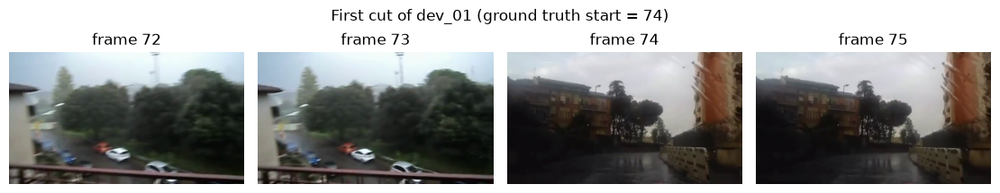

In [5]:
def show_frames(video_frames, ts, title):
    # mostra varios frames seguidos lado a lado com o numero de cada um
    ts = list(ts)
    fig, axes = plt.subplots(1, len(ts), figsize=(2.8 * len(ts), 2.2))
    for ax, t in zip(axes, ts):
        ax.imshow(cv2.cvtColor(video_frames[t], cv2.COLOR_BGR2RGB))   # o opencv da BGR, o matplotlib quer RGB
        ax.set_title(f"frame {t}")
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    return fig

cut = gts["dev_01"]["transitions"][0]["start"]
show_frames(frames["dev_01"], range(cut - 2, cut + 2), f"First cut of dev_01 (ground truth start = {cut})");

Frames are 0-indexed: `frames[t]` is frame t. The cut at `start = 74` means that frame 73 is the last frame of the old shot and frame 74 the first of the new one, so d(74), which compares `frames[73]` and `frames[74]`, is the value that must be high.

### 2.1 The three signals

**Pixel difference.** The mean absolute difference between the grey levels of the two frames, like the frame differencing in Lab 2. This is the baseline. It reacts to any change, including motion and flashes.

**Colour histogram with chi-square distance.** For each frame we build a colour histogram with `np.histogramdd` and normalise it so it sums to 1. Two histograms are compared with the chi-square distance, which we wrote ourselves: chi2 = 1/2 · sum of (h1 - h2)² / (h1 + h2), skipping the bins that are empty in both. With the 1/2 the result stays between 0 (same colours) and 1 (no colour in common). A histogram does not care where the colours are, so a moving camera barely changes it. The colour space and bins are chosen in 2.3.

**Edge Change Ratio (ECR).** Canny edges of both frames, dilated with a 5x5 kernel. We count the edges of frame t that are far from every edge of frame t-1 (entering) and the edges of t-1 that are far from every edge of t (exiting), divide each by the number of edges of its frame and keep the larger one. For frames with no edges at all (a black frame for example) we return 0 if both are empty, since nothing changed, and 1 if only one is empty, since everything changed. This also avoids dividing by zero.

The figure below is the same idea as Figure 2 of the assignment, on `dev_01`. In grey the dilated edges of t-1, in green the edges of t that fall inside them, in red the entering edges.

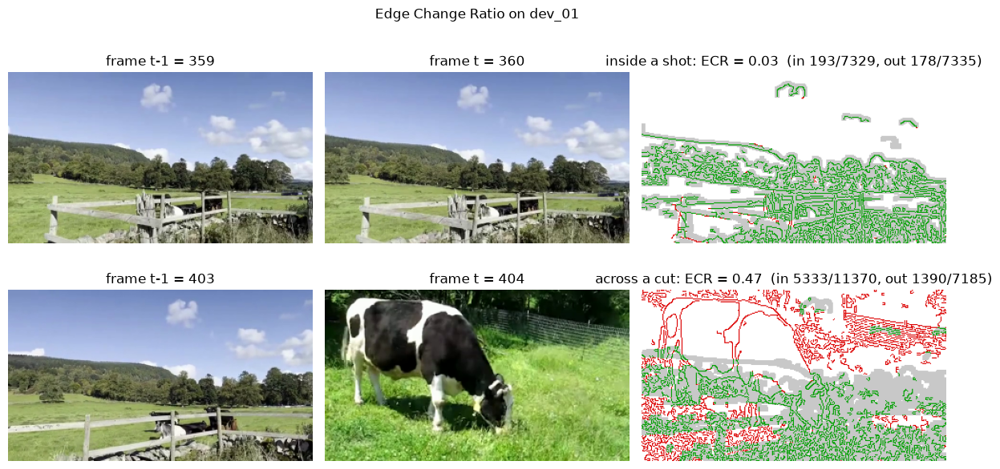

In [6]:
def show_ecr(video_frames, pairs, title):
    # para cada par (t-1, t) mostra os dois frames e a comparacao das arestas que o ECR faz
    fig, axes = plt.subplots(len(pairs), 3, figsize=(12, 3.2 * len(pairs)), squeeze=False)
    for row, (label, t) in zip(axes, pairs):
        f_prev, f_t = video_frames[t - 1], video_frames[t]
        e_prev, e_t = signals.edge_map(f_prev), signals.edge_map(f_t)
        d_prev, d_t = signals.dilate_edges(e_prev), signals.dilate_edges(e_t)

        # imagem a cores: cinzento = arestas dilatadas de t-1, verde = arestas de t la dentro, vermelho = arestas novas
        vis = np.full(e_t.shape + (3,), 255, np.uint8)
        vis[d_prev] = (200, 200, 200)
        vis[e_t & d_prev] = (0, 160, 0)
        vis[e_t & ~d_prev] = (220, 0, 0)

        x_in, x_out = np.sum(e_t & ~d_prev), np.sum(e_prev & ~d_t)
        ecr = signals.edge_change_ratio(e_prev, e_t, d_prev, d_t)
        row[0].imshow(cv2.cvtColor(f_prev, cv2.COLOR_BGR2RGB))
        row[0].set_title(f"frame t-1 = {t - 1}")
        row[1].imshow(cv2.cvtColor(f_t, cv2.COLOR_BGR2RGB))
        row[1].set_title(f"frame t = {t}")
        row[2].imshow(vis)
        row[2].set_title(f"{label}: ECR = {ecr:.2f}  (in {x_in}/{e_t.sum()}, out {x_out}/{e_prev.sum()})")
        for ax in row:
            ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    return fig

show_ecr(frames["dev_01"], [("inside a shot", 360), ("across a cut", 404)], "Edge Change Ratio on dev_01");

### 2.2 The signals over 30 seconds

750 frames of `dev_01` (30 s), with the ground truth cuts in red and the flashes in orange.

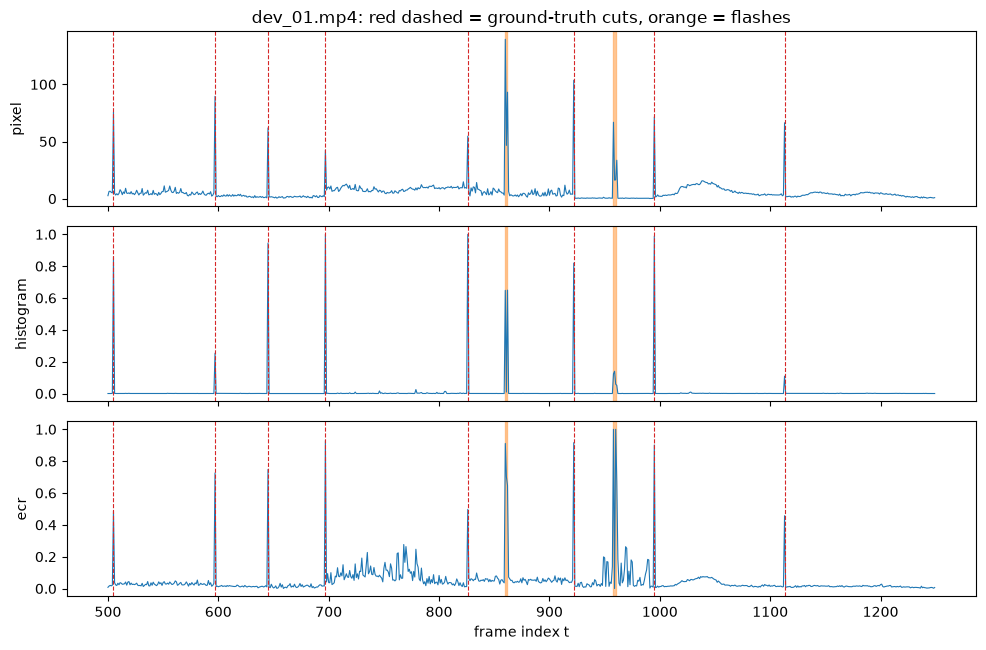

In [7]:
plotting.plot_signals(sig["dev_01"], gts["dev_01"], start=500, end=1250);

The three signals peak at the cuts but each one has its own range (0 to 255 for the pixel difference, 0 to 1 for the other two), so each needs its own threshold. The flashes give peaks as high as real cuts in the pixel difference, and one flash gives two peaks, one when it starts and one when it ends. The ECR is noisy when the camera moves fast (around frames 700 to 800).

### 2.3 Choosing the colour histogram

For each colour space and number of bins we try many thresholds on the two dev videos and keep the best F1. To score we always use `metrics.match_cuts` and add up TP, FP and FN over the two videos before computing P, R and F1, as the assignment says (`signals.score_cuts`).

In [8]:
configs = [("rgb", (8, 8, 8)), ("hsv", (16, 4, 4)), ("hsv", (32, 8, 4)), ("hsv", (16, 4, 1)),
           ("hsv", (32, 4, 1)), ("hsv", (16, 8, 1)), ("hsv", (16, 2, 1))]
print(f"{'space':6s} {'bins':12s} {'T':>7s} {'P':>6s} {'R':>6s} {'F1':>6s}")
for space, bins in configs:
    d_hist = {n: signals.histogram_signal(frames[n], space, bins) for n in DEV}
    T, p, r, f1 = signals.best_f1(signals.sweep(d_hist, gts, thresholds_for(d_hist)))
    print(f"{space:6s} {str(bins):12s} {T:7.4f} {p:6.3f} {r:6.3f} {f1:6.3f}")

space  bins               T      P      R     F1


rgb    (8, 8, 8)     0.2917  0.644  0.929  0.760


hsv    (16, 4, 4)    0.3812  0.717  0.943  0.815


hsv    (32, 8, 4)    0.4278  0.705  0.957  0.812


hsv    (16, 4, 1)    0.3092  0.827  0.886  0.855


hsv    (32, 4, 1)    0.3749  0.855  0.843  0.849


hsv    (16, 8, 1)    0.3083  0.719  0.914  0.805


hsv    (16, 2, 1)    0.2087  0.884  0.871  0.878


HSV works better than RGB, and the biggest gain comes from dropping the brightness channel V (one single bin for V). Flashes, light changes and auto exposure mostly change the brightness, while a cut changes the colours. Few saturation bins also help, because small changes in saturation inside a shot stay in the same bin. We keep HSV with 16 bins for H, 2 for S and 1 for V (`signals.HIST_BINS`), which is what `sig` above already uses.

### 2.4 One threshold per signal

Each signal on its own, at the threshold with the best F1 on the dev videos, per video and for the two together.

In [9]:
curves = {}
best_T = {}
for name in ["pixel", "histogram", "ecr"]:
    d = {n: sig[n][name] for n in DEV}
    results = signals.sweep(d, gts, thresholds_for(d))
    curves[name] = [(T, p, r) for T, p, r, f1 in results]   # o plot_pr_curve quer (T, P, R)
    best_T[name] = signals.best_f1(results)[0]

for name in ["pixel", "histogram", "ecr"]:
    counts = []
    for n in DEV:
        cuts = signals.detect_cuts(sig[n][name], best_T[name])
        counts.append(metrics.evaluate_video(gts[n], {"transitions": [{"start": t} for t in cuts]}))
    print(f"\n{name}: T = {best_T[name]:.4f}")
    metrics.print_table([(n, c) for n, c in zip(DEV, counts)] + [("DEV", metrics.sum_counts(counts))])


pixel: T = 48.4580
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.667  0.944   0.782       6/6    0.000    0.000     0.000
dev_02      0.732  0.882   0.800       6/6    0.000    0.000     0.000
DEV         0.696  0.914   0.790     12/12    0.000    0.000     0.000

histogram: T = 0.2087
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.906  0.806   0.853       2/6    0.000    0.000     0.000
dev_02      0.865  0.941   0.901       1/6    0.000    0.000     0.000
DEV         0.884  0.871   0.878      3/12    0.000    0.000     0.000

ecr: T = 0.7227
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.615  0.444   0.516       3/6    0.000    0.000     0.000
dev_02      0.719  0.676   0.697       4/6    0.000    0.000     0.000
DEV         0.672  0.557   0.609      7/12    0.000    0.000     0.000


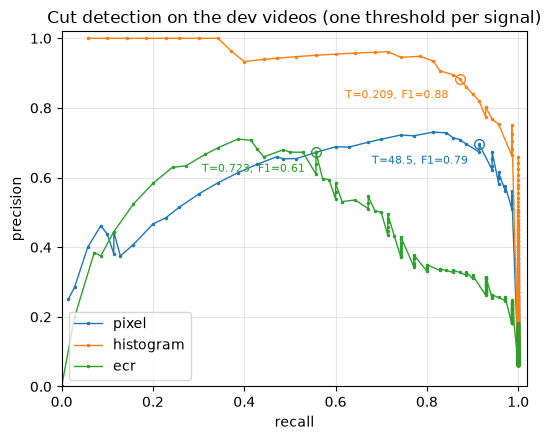

In [10]:
plotting.plot_pr_curve(curves, title="Cut detection on the dev videos (one threshold per signal)");

The histogram is the best single signal and also the one that copes best with flashes, only 3 of the 12 flashes give a false cut, against all 12 with the pixel difference. The pixel difference finds almost every cut but with a lot of false alarms. The ECR is the worst, with F1 around 0.6. We tried other Canny thresholds and dilation sizes from 3 to 9 and it always stayed around 0.6. Its false alarms come from fast camera motion, where the edges move more than the dilation covers, and its misses from cuts between frames with similar edges or with very few edges.

### 2.5 Combining two signals

The histogram and the ECR make different mistakes. The histogram misses cuts between scenes with similar colours and the ECR fires when the camera moves. So we try declaring a cut only when both signals are above their own threshold (`signals.detect_cuts_two`), and choose the two thresholds together by testing every pair on the dev videos.

In [11]:
# para cada par de sinais testamos 60 x 60 pares de thresholds
grid = {name: thresholds_for({n: sig[n][name] for n in DEV}, 0.9 if name == "histogram" else 0.8, 0.999, 60)
        for name in ["pixel", "histogram", "ecr"]}

best_pair = {}
for a, b in [("histogram", "ecr"), ("histogram", "pixel"), ("pixel", "ecr")]:
    d_a = {n: sig[n][a] for n in DEV}
    d_b = {n: sig[n][b] for n in DEV}
    t_a, t_b, p, r, f1 = signals.best_f1(signals.sweep_two(d_a, d_b, gts, grid[a], grid[b]))
    best_pair[(a, b)] = (t_a, t_b)
    print(f"{a} > {t_a:.4f} and {b} > {t_b:.4f}:  P={p:.3f} R={r:.3f} F1={f1:.3f}")

# os thresholds do detetor da parte 1 (histograma e ECR), usados outra vez na parte 2
T_HIST_P1, T_ECR_P1 = best_pair[("histogram", "ecr")]

histogram > 0.2027 and ecr > 0.3753:  P=0.939 R=0.886 F1=0.912


histogram > 0.2027 and pixel > 27.9946:  P=0.925 R=0.886 F1=0.905


pixel > 53.9816 and ecr > 0.3753:  P=0.741 R=0.857 F1=0.795


In [12]:
# o detetor da parte 1 com os dois thresholds escolhidos, video a video
print(f"histogram > {T_HIST_P1:.4f} and ECR > {T_ECR_P1:.4f}")
counts = []
for n in DEV:
    cuts = signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"], T_HIST_P1, T_ECR_P1)
    counts.append(metrics.evaluate_video(gts[n], {"transitions": [{"start": t} for t in cuts]}))
metrics.print_table([(n, c) for n, c in zip(DEV, counts)] + [("DEV", metrics.sum_counts(counts))])

histogram > 0.2027 and ECR > 0.3753
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.906  0.806   0.853       2/6    0.000    0.000     0.000
dev_02      0.971  0.971   0.971       1/6    0.000    0.000     0.000
DEV         0.939  0.886   0.912      3/12    0.000    0.000     0.000


Histogram and ECR together is the best configuration on the dev set, F1 0.912 against 0.878 for the histogram alone. The histogram threshold goes a bit down, so we catch some cuts between similar colours, and the ECR condition removes most of the false alarms caused by motion. These thresholds (`T_HIST_P1` and `T_ECR_P1`) are the Part 1 detector. In Part 2 the verification lets us replace it with a simpler and less strict one (Section 3.4). Flashes still give 3 false cuts out of 12, because a flash changes both the colours and the edges. That is what Part 2 is for.

### 2.6 Checking the metrics

The quick test suggested in the assignment. Giving the ground truth as the prediction must give F1 = 1. Shifting every cut by 3 frames (more than the tolerance of 2) must give F1 = 0 for the cuts. Putting every shot in the same scene must give recall 1 and a low precision.

In [13]:
gt = gts["dev_01"]
perfect = {"transitions": gt["transitions"], "scenes": {str(s["id"]): s["scene"] for s in gt["shots"]}}
shifted = {"transitions": [{"start": t["start"] + 3} for t in gt["transitions"]],
           "scenes": {str(s["id"]): 0 for s in gt["shots"]}}
metrics.print_table([("perfect", metrics.evaluate_video(gt, perfect)),
                     ("shift+3/1 sc", metrics.evaluate_video(gt, shifted))])

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
perfect     1.000  1.000   1.000       0/6    1.000    1.000     1.000
shift+3/1 sc  0.000  0.000   0.000       0/6    0.015    1.000     0.030


## 3. Part 2 - False alarms

A flash lasts 1 to 3 frames and changes the brightness a lot without changing the shot. The frames before and after it show the same content, but the dissimilarity signals jump when the flash starts and again when it ends, so a threshold low enough to find the cuts also fires on it. Below, the first flash of `dev_01` (its position comes from the `distractors` of the ground truth, which is only used to evaluate and illustrate, never by the detector).

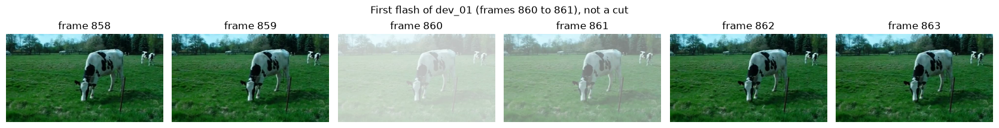

In [14]:
flash = gts["dev_01"]["distractors"][0]
show_frames(frames["dev_01"], range(flash["start"] - 2, flash["end"] + 3),
            f"First flash of dev_01 (frames {flash['start']} to {flash['end']}), not a cut");

### 3.1 Where the false alarms come from

Before fixing the false alarms we look at them: the candidates of the Part 1 detector (histogram and ECR, `T_HIST_P1` and `T_ECR_P1`) that are not within 2 frames of any ground-truth cut. We also check whether they fall on one of the flashes listed in the ground truth (`distractors`), which we use only to analyse the errors, never in the detector.

dev_01 frame 860: flash at frames 860 to 861
dev_01 frame 862: flash at frames 860 to 861
dev_01 frame 2837: flash at frames 2837 to 2838
dev_02 frame 1064: flash at frames 1064 to 1065


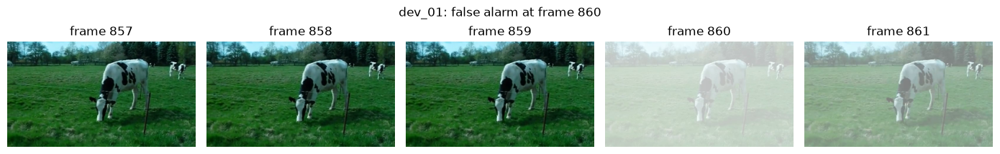

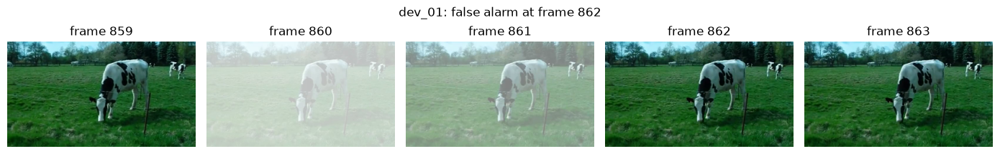

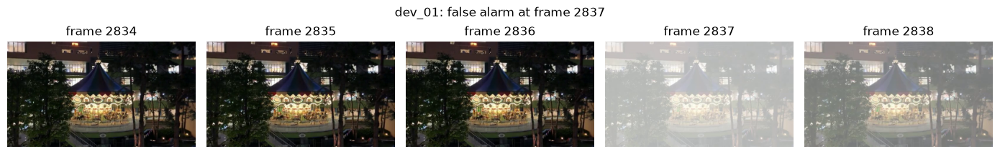

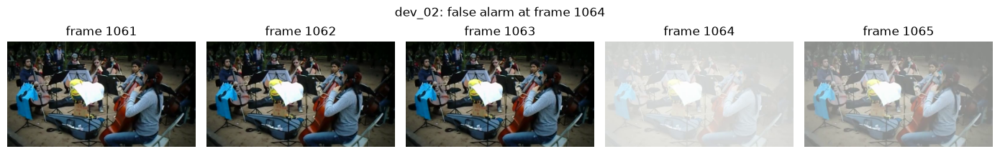

In [15]:
def false_positives(pred_cuts, gt_cuts, tol=metrics.TOLERANCE):
    # os cortes previstos que nao tem nenhum corte do ground truth a menos de tol frames
    return [p for p in pred_cuts if not any(abs(p - g) <= tol for g in gt_cuts)]


def near_flash(t, distractors, tol=metrics.TOLERANCE):
    # o flash do ground truth a menos de tol frames de t, ou None (os flashes so servem para analisar os erros)
    for d in distractors:
        if d["start"] - tol <= t <= d["end"] + tol:
            return d
    return None


p1_fps = {}
for n in DEV:
    cands_p1 = signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"], T_HIST_P1, T_ECR_P1)
    p1_fps[n] = false_positives(cands_p1, [c["start"] for c in gts[n]["transitions"]])
    for t in p1_fps[n]:
        flash = near_flash(t, gts[n]["distractors"])
        print(f"{n} frame {t}: " + (f"flash at frames {flash['start']} to {flash['end']}" if flash else "no flash"))

for n in DEV:
    for t in p1_fps[n]:
        show_frames(frames[n], range(t - 3, t + 2), f"{n}: false alarm at frame {t}");

On the dev videos all 4 false alarms of the Part 1 detector are flashes, and one flash of `dev_01` gives two of them: one when the light goes on (frame 860) and one when it goes off (frame 862, the first frame after the flash). A flash washes out the colours and the edges of the whole frame, so it fools the histogram and the ECR at the same time. In all of them the frames before and after the flash show exactly the same content, which is what the verification checks.

### 3.2 Matching two frames with SIFT

For every candidate cut t we compare frame t - g with frame t + g, with g = 4 (`verify.GAP`), and not frames t - 1 and t: a flash lasts up to 3 frames, and with the gap neither of the two frames is a flash frame. If t is a real cut the two frames belong to different shots, and if it is a false alarm they belong to the same shot.

We detect SIFT keypoints and descriptors on the grey frames, and for every descriptor of the first frame we find its two nearest neighbours in the second one (`BFMatcher.knnMatch` with k = 2). Lowe's ratio test keeps a match only when the best neighbour is clearly closer than the second one (distance ratio below 0.75), which removes most ambiguous matches on repeated textures (`verify.sift_matches`).

Optionally we only count the RANSAC inliers of a homography between the two frames (`cv2.findHomography`, reprojection error up to 5 pixels). When the two frames show the same scene, the true matches all follow the same camera motion, while wrong matches point in random directions and do not agree with any single homography. A homography needs 4 matches, so with fewer than 4 we return 0 inliers: there are too few matches to say that the content is the same.

Many matches mean that the two frames show the same content, so the candidate is rejected as a false alarm. A candidate closer than g frames to the start or the end of the video cannot be checked, so we keep it as a cut (this is rare, videos do not start or end with a cut).

The check below shows the idea: across the cut at frame 74, frames 70 and 78 share only 2 matches (0 RANSAC inliers), while frames 356 and 364 of the same shot share 187 matches (164 inliers). A black frame has no keypoints and gives 0 matches without crashing.

In [16]:
# sanity check: a real cut must give few matches and two frames of the same shot many
cases = [("dev_01", 70, 78), ("dev_01", 356, 364), ("dev_01", 0, 340)]
for n, t1, t2 in cases:
    f1, f2 = frames[n][t1], frames[n][t2]
    print(f"{n} frames {t1} and {t2}: {verify.count_matches(f1, f2, use_ransac=False)} good matches, "
          f"{verify.count_matches(f1, f2, use_ransac=True)} RANSAC inliers")

# um frame sem keypoints nao pode rebentar
black = np.zeros_like(frames["dev_01"][0])
print("black frame:", verify.count_matches(black, frames["dev_01"][356]))
    

dev_01 frames 70 and 78: 2 good matches, 0 RANSAC inliers
dev_01 frames 356 and 364: 187 good matches, 164 RANSAC inliers
dev_01 frames 0 and 340: 0 good matches, 0 RANSAC inliers
black frame: 0


### 3.3 Choosing the minimum number of matches

The SIFT matches of each candidate are computed once (`verify.candidate_matches`), then we try many values of the minimum number of matches on the two dev videos, with all the good matches and with the RANSAC inliers only.

In [17]:
# candidatos do detetor da parte 1 (histograma e ECR) nos dois videos dev
cands = {n: signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"], T_HIST_P1, T_ECR_P1) for n in DEV}

NO_VERIFY = 10**9   # um min_matches enorme nunca rejeita nada, e o detetor da parte 1 sozinho
values = list(range(0, 301)) + [NO_VERIFY]

matches = {}   # matches[use_ransac][video] = {candidato: numero de matches}, reusado na 3.5 e na 3.6
for use_ransac in [False, True]:
    start = time.time()
    m = {n: verify.candidate_matches(frames[n], cands[n], use_ransac=use_ransac) for n in DEV}
    elapsed = time.time() - start
    matches[use_ransac] = m

    results = verify.sweep_min_matches(cands, m, gts, values)
    best = signals.best_f1(results) 
    same_f1 = [res[0] for res in results if res[-1] == best[-1]]   # todos os valores com o melhor F1

    # separamos os matches dos candidatos que sao cortes verdadeiros e dos que sao falsos alarmes
    true_m, false_m = [], []
    for n in DEV:
        gt_cuts = [c["start"] for c in gts[n]["transitions"]]
        for t, k in m[n].items():
            is_cut = any(abs(t - g) <= metrics.TOLERANCE for g in gt_cuts)
            (true_m if is_cut else false_m).append(k)

    _, p0, r0, f0 = results[-1]
    print(f"{'RANSAC inliers' if use_ransac else 'all good matches'} (SIFT on every candidate in {elapsed:.1f} s)")
    print(f"  no verification:  P={p0:.3f} R={r0:.3f} F1={f0:.3f}")
    print(f"  best:             P={best[1]:.3f} R={best[2]:.3f} F1={best[3]:.3f}, "
          f"for every min_matches from {same_f1[0]} to {same_f1[-1]}")
    print(f"  real cuts have at most {max(true_m)}, false alarms at least {min(false_m)} "
          f"({len(true_m)} real cuts, {len(false_m)} false alarms)")

# o valor escolhido para estes candidatos (revisto na 3.4, com mais candidatos)
chosen = verify.sweep_min_matches(cands, matches[True], gts, [40])[0]
print(f"\nchosen: RANSAC inliers, min_matches=40: P={chosen[1]:.3f} R={chosen[2]:.3f} F1={chosen[3]:.3f}")

all good matches (SIFT on every candidate in 1.2 s)
  no verification:  P=0.939 R=0.886 F1=0.912
  best:             P=1.000 R=0.886 F1=0.939, for every min_matches from 14 to 218
  real cuts have at most 13, false alarms at least 218 (62 real cuts, 4 false alarms)


RANSAC inliers (SIFT on every candidate in 1.2 s)
  no verification:  P=0.939 R=0.886 F1=0.912
  best:             P=1.000 R=0.886 F1=0.939, for every min_matches from 8 to 213
  real cuts have at most 7, false alarms at least 213 (62 real cuts, 4 false alarms)

chosen: RANSAC inliers, min_matches=40: P=1.000 R=0.886 F1=0.939



The verification removes every false alarm of the Part 1 detector on the dev videos (precision 1.0) without losing a single real cut, so F1 goes from 0.912 to 0.939. Recall does not change: the cuts that are still missed were never candidates, which is what 3.4 deals with.

There is a large gap between the two kinds of candidates. Real cuts share at most 13 matches (7 RANSAC inliers), coincidental matches between unrelated frames, while false alarms share more than 200, because both frames show the same shot. Every value inside the gap gives the same F1, and `signals.best_f1`, which returns the first one, picks a value just above the real cuts (14, or 8 with RANSAC). We prefer a value in the middle of the gap, because the test videos contain harder cases: cuts between takes of the same location will give more matches, and fast camera motion fewer. We count RANSAC inliers, since RANSAC removes most of the coincidental matches of the real cuts (at most 7 instead of 13) while the false alarms keep almost all of theirs, which makes the gap relatively wider. For these candidates we would choose a minimum of 40, roughly the geometric mean of 7 and 213.

Only 4 false alarms are left at this point, which is a small sample, so we check this choice again in 3.4, where lowering the detector threshold gives many more candidates and the gap almost disappears.

### 3.4 Lowering the detector threshold

The verification removes false alarms, so the detector can be less strict: a lower threshold finds more cuts (higher recall) and the verification removes the extra false alarms. The cuts that the Part 1 detector misses were never candidates, so the verification cannot bring them back. We try lower thresholds for the histogram, given by percentiles of its values on the dev videos (`T_HIST_P1` is about the 0.99 percentile), and for each one the best minimum number of RANSAC inliers. The SIFT matches of a frame are computed only once and kept in a cache, because the same frame is a candidate for many thresholds.

In [18]:
# a cache dos matches: o mesmo frame t e candidato em varios thresholds, assim o SIFT de cada t so corre uma vez
match_cache = {n: {} for n in DEV}

def cached_matches(n, cands):
    new = [t for t in cands if t not in match_cache[n]]
    match_cache[n].update(verify.candidate_matches(frames[n], new))
    return {t: match_cache[n][t] for t in cands if t in match_cache[n]}


def evaluate_detector(cands):
    # verifica os candidatos de cada video dev e testa todos os min_matches de 1 a 300
    # devolve o numero de candidatos, o melhor (min_matches, P, R, F1) e todos os min_matches com esse F1
    m = {n: cached_matches(n, cands[n]) for n in DEV}
    results = verify.sweep_min_matches(cands, m, gts, range(1, 301))
    best = signals.best_f1(results)
    same_f1 = [res[0] for res in results if res[-1] == best[-1]]
    return sum(len(c) for c in cands.values()), best, same_f1


def with_nms(cands):
    # non-maximum suppression no histograma: um candidato por pico do sinal
    return {n: signals.local_maxima(sig[n]["histogram"], cands[n]) for n in DEV}

In [19]:
# thresholds mais baixos do que o da parte 1, dados por percentis dos valores do histograma
hist_T = thresholds_for({n: sig[n]["histogram"] for n in DEV}, 0.97, 0.995, 6)
ecr_T = thresholds_for({n: sig[n]["ecr"] for n in DEV}, 0.80, 0.95, 4)

n_p1, best_p1, _ = evaluate_detector({n: signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"],
                                                                 T_HIST_P1, T_ECR_P1) for n in DEV})
print(f"Part 1 detector (histogram and ECR): {n_p1} candidates, F1 = {best_p1[-1]:.3f} after verification\n")
print("all F1 values are after verification, with the best minimum number of inliers")
print(f"{'':8s} {'histogram alone':>16s} {'with NMS':>16s} {'hist and ECR':>14s}")
print(f"{'hist T':>8s} {'cands':>7s} {'F1':>8s} {'cands':>7s} {'F1':>8s} {'best F1':>14s}")
for th in hist_T:
    alone = {n: signals.detect_cuts(sig[n]["histogram"], th) for n in DEV}
    n_a, best_a, _ = evaluate_detector(alone)
    n_n, best_n, _ = evaluate_detector(with_nms(alone))
    # o ECR como segunda condicao, com o melhor dos 4 thresholds testados
    f1_ecr = max(evaluate_detector({n: signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"], th, te)
                                    for n in DEV})[1][-1] for te in ecr_T)
    print(f"{th:8.4f} {n_a:7d} {best_a[-1]:8.3f} {n_n:7d} {best_n[-1]:8.3f} {f1_ecr:14.3f}")

Part 1 detector (histogram and ECR): 66 candidates, F1 = 0.939 after verification

all F1 values are after verification, with the best minimum number of inliers
          histogram alone         with NMS   hist and ECR
  hist T   cands       F1   cands       F1        best F1


  0.0129     227    0.839     131    0.979          0.865


  0.0155     190    0.861     119    0.979          0.883


  0.0212     152    0.885     104    0.986          0.913


  0.0416     114    0.958      93    0.986          0.958


  0.1681      76    0.948      72    0.955          0.955
  0.4898      38    0.679      37    0.679          0.679


Lowering the threshold makes the recall go up, but many of the new candidates are duplicates: with a low threshold the frames right after a cut also go above it. They are more than 2 frames away from the cut, so they count as false alarms, and the verification cannot remove them, because frames t - 4 and t + 4 are still on both sides of the cut and share no matches. Non-maximum suppression (`signals.local_maxima`) keeps a candidate only when its histogram distance is the largest within 5 frames on each side, so every peak of the signal gives one candidate (the shortest dev shot has 29 frames, so two real cuts never fall in the same window). With it, F1 after verification goes well above the 0.939 of 3.3. Adding the ECR as a second condition helps much less than NMS, so the final detector uses the histogram alone.

In [20]:
# a configuracao final (tp1.T_HIST com NMS): como o F1 muda com o numero minimo de inliers
final_cands = with_nms({n: signals.detect_cuts(sig[n]["histogram"], tp1.T_HIST) for n in DEV})
final_m = {n: cached_matches(n, final_cands[n]) for n in DEV}

print(f"histogram > {tp1.T_HIST} with NMS: {sum(len(c) for c in final_cands.values())} candidates")
print(f"{'min_matches':>11s} {'P':>6s} {'R':>6s} {'F1':>6s}")
for mm, p, r, f1 in verify.sweep_min_matches(final_cands, final_m, gts, [5, 6, 7, 8, 10, 12, 14, 15, 20, 30, 40]):
    print(f"{mm:11d} {p:6.3f} {r:6.3f} {f1:6.3f}")

# inliers dos candidatos que sao cortes verdadeiros e dos falsos alarmes
true_m, false_m = [], []
for n in DEV:
    gt_cuts = [c["start"] for c in gts[n]["transitions"]]
    for t, k in final_m[n].items():
        is_cut = any(abs(t - g) <= metrics.TOLERANCE for g in gt_cuts)
        (true_m if is_cut else false_m).append(k)
print(f"\nreal cuts have at most {max(true_m)} inliers; false alarms with fewer than 40: {sorted(k for k in false_m if k < 40)}")

chosen = verify.sweep_min_matches(final_cands, final_m, gts, [verify.MIN_MATCHES])[0]
print(f"chosen: min_matches={verify.MIN_MATCHES}: P={chosen[1]:.3f} R={chosen[2]:.3f} F1={chosen[3]:.3f}")

histogram > 0.0416 with NMS: 93 candidates
min_matches      P      R     F1
          5  0.985  0.914  0.948
          6  0.985  0.957  0.971
          7  0.986  0.986  0.986
          8  0.959  1.000  0.979
         10  0.959  1.000  0.979
         12  0.959  1.000  0.979
         14  0.959  1.000  0.979
         15  0.946  1.000  0.972
         20  0.909  1.000  0.952
         30  0.886  1.000  0.940
         40  0.875  1.000  0.933

real cuts have at most 7 inliers; false alarms with fewer than 40: [0, 7, 7, 14, 15, 17, 19, 24, 28, 38]
chosen: min_matches=10: P=0.959 R=1.000 F1=0.979


With many more candidates the gap of 3.3 disappears. Real cuts still share at most 7 RANSAC inliers, but some false alarms now share very few (we look at them in Section 6), and the minimum of 40 chosen in 3.3 would keep many of them. The best F1 on the dev videos is reached only at exactly 7, which rejects a real cut with 7 inliers together with two false alarms with 7: it depends on a single value. Every value from 8 to 14 gives the same F1 with recall 1.0, so, as in 3.3, we take the middle of that range: `verify.MIN_MATCHES = 10`, about the geometric mean of 7 and 14.

The final configuration of Parts 1 and 2, in `tp1.py`, is: histogram distance above `tp1.T_HIST` (0.0416, the 0.985 percentile of the dev values), non-maximum suppression over 5 frames on each side, and SIFT verification that rejects the candidates with at least 10 RANSAC inliers between frames t - 4 and t + 4. On the dev videos it gives P = 0.959, R = 1.000 and F1 = 0.979, against 0.912 for the Part 1 detector alone and 0.939 for the Part 1 detector with verification. The margin between real cuts and false alarms is now small (7 against 14 inliers), which is a risk on the test videos.

### 3.5 With and without verification

Cut detection and flash false alarms on the dev videos, for the Part 1 detector and for the final detector of 3.4, without and with verification. The scene columns are 0 because scenes are only predicted in Part 3.

In [21]:
def show_table(title, cuts_per_video):
    # tabela do metrics (P, R, F1 e flash-FA) para os dois videos dev e o total
    counts = [metrics.evaluate_video(gts[n], {"transitions": [{"start": t} for t in cuts_per_video[n]]}) for n in DEV]
    print(title)
    metrics.print_table([(n, c) for n, c in zip(DEV, counts)] + [("DEV", metrics.sum_counts(counts))])
    print()

part1_cuts = {n: signals.detect_cuts_two(sig[n]["histogram"], sig[n]["ecr"], T_HIST_P1, T_ECR_P1) for n in DEV}
final_cuts = {n: verify.verify_cuts(final_cands[n], final_m[n], verify.MIN_MATCHES) for n in DEV}

show_table("Part 1 detector (histogram and ECR), no verification", part1_cuts)
show_table("Final detector (histogram with NMS), no verification", final_cands)
show_table("Final detector with verification (tp1.py)", final_cuts)

# o que a verificacao rejeitou, e os falsos alarmes que sobram
for n in DEV:
    gt_cuts = [c["start"] for c in gts[n]["transitions"]]
    rejected = [t for t in final_cands[n] if t not in final_cuts[n]]
    real_rejected = len(rejected) - len(false_positives(rejected, gt_cuts))
    print(f"{n}: {len(rejected)} candidates rejected, {real_rejected} of them real cuts")
    for t in false_positives(final_cuts[n], gt_cuts):
        flash = near_flash(t, gts[n]["distractors"])
        print(f"  false alarm left at frame {t}: {final_m[n].get(t)} inliers" + (", flash" if flash else ""))

Part 1 detector (histogram and ECR), no verification
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.906  0.806   0.853       2/6    0.000    0.000     0.000
dev_02      0.971  0.971   0.971       1/6    0.000    0.000     0.000
DEV         0.939  0.886   0.912      3/12    0.000    0.000     0.000

Final detector (histogram with NMS), no verification
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.750  1.000   0.857       6/6    0.000    0.000     0.000
dev_02      0.756  1.000   0.861       6/6    0.000    0.000     0.000
DEV         0.753  1.000   0.859     12/12    0.000    0.000     0.000

Final detector with verification (tp1.py)
video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.973  1.000   0.986       0/6    0.000    0.000     0.000
dev_02      0.944  1.000   0.971       1/6    0.000    0.000     0.000
DEV         0.959  1.000   0.979      1/12    0.000    0.000     0.00

Without verification the final detector finds every cut (recall 1.0) but also fires on all 12 flashes, so its precision drops to 0.753. The verification rejects 20 of its candidates, none of them a real cut, and only 1 of the 12 flashes is still taken for a cut, against 3 for the Part 1 detector. F1 goes from 0.859 to 0.979.

Three false alarms are left. Frame 3342 of `dev_01` is a fast camera pan with strong motion blur, and frame 3090 of `dev_02` is a camera that rotates quickly above a car: in both, the two compared frames show the same scene, but the blur and the large motion leave only 7 RANSAC inliers. Frame 1867 of `dev_02` is a flash on a view of the sea, where the water and the sky give very few stable keypoints, so the frames before and after the flash share no inliers at all. These are the limits of the verification: it needs sharp, textured frames to recognise the same content.

### 3.6 A false alarm removed by verification

Frame 2837 of `dev_01` is one of the flashes that the Part 1 detector takes for a cut (3.1). Below, the frames around it and the SIFT matches between frames t - 4 and t + 4, next to the same comparison across a real cut.

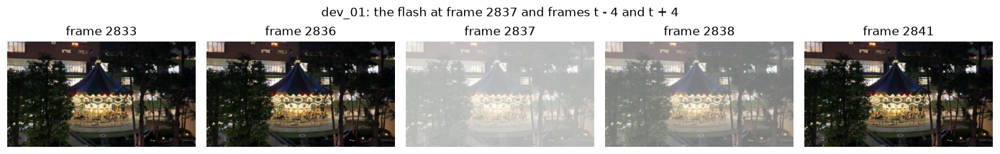

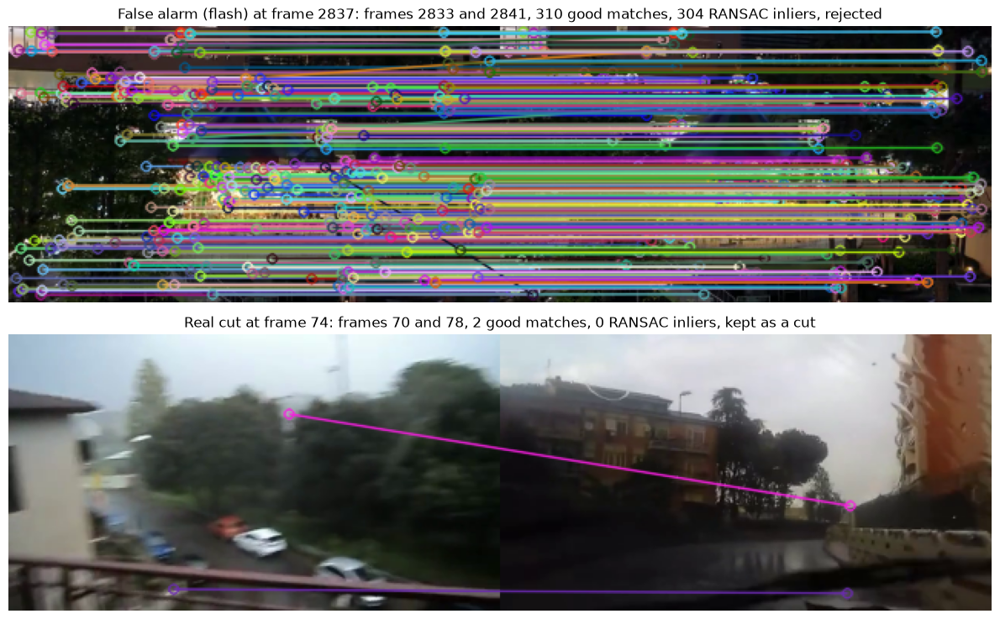

In [22]:
# um falso alarme da parte 1 (o flash do frame 2837 do dev_01) contra um corte verdadeiro (frame 74)
g = verify.GAP
examples = [("dev_01", 2837, "False alarm (flash)"), ("dev_01", 74, "Real cut")]
show_frames(frames["dev_01"], [2837 - g, 2836, 2837, 2838, 2837 + g], "dev_01: the flash at frame 2837 and frames t - 4 and t + 4");

fig, axes = plt.subplots(len(examples), 1, figsize=(12, 7.5))
for ax, (n, t, label) in zip(axes, examples):
    f1, f2 = frames[n][t - g], frames[n][t + g]
    kp1, kp2, good = verify.sift_matches(f1, f2)
    inliers = verify.count_matches(f1, f2, use_ransac=True)
    decision = "rejected" if inliers >= verify.MIN_MATCHES else "kept as a cut"
    vis = cv2.drawMatches(f1, kp1, f2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))   # o drawMatches da BGR como o resto do opencv
    ax.set_title(f"{label} at frame {t}: frames {t - g} and {t + g}, {len(good)} good matches, "
                 f"{inliers} RANSAC inliers, {decision}")
    ax.axis("off")
fig.tight_layout()

Frames 2833 and 2841 are outside the flash and show the same carousel, so 310 matches pass the ratio test and 304 of them are RANSAC inliers, far above the minimum of 10: the candidate is rejected. The lines are almost all horizontal and parallel, because the camera barely moves in 8 frames, which is exactly the kind of agreement RANSAC looks for. Across the real cut at frame 74, frames 70 and 78 show two different streets and share only 2 matches, which do not agree with any homography (0 inliers), so that candidate is kept as a cut.

## 4. Part 3 - Recurring scenes

Here we group the shots that come from the same scene. As the assignment asks, we use the ground truth shots (`gt["shots"]`) and not the cuts we detect, so the mistakes of Parts 1 and 2 do not change the results of this part. All the code is in `recurring.py`.

**Keyframes.** Each shot is represented by n keyframes spread evenly inside the shot (`recurring.keyframes`). With n = 1 it is the middle frame, with n = 3 the frames at 1/4, 1/2 and 3/4 of the shot. We never take the first or the last frame of a shot, because they are right next to a cut.

**Similarity between two keyframes.** We compare them in two ways:
- colour: 1 - χ², with the same HSV histogram (16x2x1 bins) and the same χ² distance as in Part 1, so 1 means the same colours;
- local features: the number of SIFT matches that pass Lowe's ratio test (0.75, as in Part 2), without RANSAC.

**Similarity between two shots.** With n keyframes per shot there are n x n pairs of keyframes, and we try two ways of turning them into one number: the best pair (`max`) and the average over all pairs (`mean`). This gives a shot x shot similarity matrix, and `grouping.group_shots` links every pair of shots with similarity >= threshold and returns the connected components as scenes.

The histogram and the SIFT descriptors of each keyframe are computed only once (`recurring.keyframe_features`) and reused for every pair. Recomputing SIFT for every pair, like `verify.sift_matches` does, would be too slow here because each keyframe is compared with all the others.

### 4.1 Comparing the strategies

For 1, 3, 5 and 7 keyframes per shot, with colour and with SIFT, and with `max` and `mean`, we try 400 thresholds on the two dev videos and keep the best pairwise F1. As in Part 1, the counts of the two videos are added before computing P, R and F1.

In [23]:
# features dos keyframes para cada numero de keyframes, calculadas uma vez para os dois videos dev
KEYFRAMES = [1, 3, 5, 7]
start = time.time()
scene_feats = {k: {n: recurring.shot_features(frames[n], gts[n]["shots"], k) for n in DEV} for k in KEYFRAMES}
print(f"keyframe features in {time.time() - start:.1f} s")


def scene_thresholds(sims, num=400):
    # como na parte 1, os thresholds a testar sao quantis dos valores da matriz (so os pares a < b)
    values = np.concatenate([s[np.triu_indices(len(s), 1)] for s in sims.values()])
    return np.unique(np.quantile(values, np.linspace(0.80, 0.9999, num)))


scene_sims = {}     # (keyframes, kind, combine) -> {video: matriz}
scene_curves = {}   # (keyframes, kind, combine) -> lista de (T, P, R, F1)
print(f"{'keyframes':>9s} {'similarity':>10s} {'combine':>7s} {'best T':>8s} {'P':>6s} {'R':>6s} {'F1':>6s} {'time':>6s}")
for k in KEYFRAMES:
    for kind in ["color", "sift"]:
        for combine in (["max"] if k == 1 else ["max", "mean"]):   # com 1 keyframe o max e a media sao iguais
            start = time.time()
            sims = {n: recurring.similarity_matrix(scene_feats[k][n], kind, combine) for n in DEV}
            t = time.time() - start
            res = recurring.sweep_scenes(sims, gts, scene_thresholds(sims))
            T, p, r, f1 = signals.best_f1(res)
            scene_sims[k, kind, combine] = sims
            scene_curves[k, kind, combine] = res
            print(f"{k:9d} {kind:>10s} {combine:>7s} {T:8.3f} {p:6.3f} {r:6.3f} {f1:6.3f} {t:5.1f}s")

keyframe features in 12.1 s
keyframes similarity combine   best T      P      R     F1   time


        1      color     max    0.961  1.000  0.677  0.808   0.0s


        1       sift     max   23.188  1.000  0.742  0.852   0.5s


        3      color     max    0.971  1.000  0.871  0.931   0.1s


        3      color    mean    0.914  0.962  0.806  0.877   0.1s


        3       sift     max   34.722  1.000  0.871  0.931   5.3s


... (5 outputs left out)

        7      color     max    0.981  1.000  0.968  0.984   0.5s


        7      color    mean    0.905  0.960  0.774  0.857   0.5s


        7       sift     max   41.204  1.000  0.935  0.967  30.1s


        7       sift    mean   10.589  0.966  0.903  0.933  30.6s


More keyframes help a lot. With 1 keyframe the precision is already 1.0 but the recall is low (0.68 for colour, 0.74 for SIFT), because the middle frame of a shot often does not look like the middle frame of the other shots of its scene: the camera moved, or someone walked in front of it. With 5 keyframes and `max` the recall goes up to 0.97, and the F1 of colour goes from 0.81 to 0.98. Going from 5 to 7 keyframes does not change colour and helps SIFT a little, but the SIFT matrix takes twice as long.

`max` is always better than `mean`. Two shots of the same scene only need one moment that looks alike, while the mean is pulled down by the keyframes that do not match.

Colour is better than SIFT on the dev videos (0.984 against 0.967 at best). Inside a scene the camera moves, people walk by and there is motion blur, which removes SIFT matches, while the colours stay almost the same. SIFT is also about 50 times slower here. We keep colour with 5 keyframes and `max`, which gives the same F1 as 7 keyframes for less work.

### 4.2 Choosing the threshold

The best F1 alone does not say how safe a threshold is. Below is the F1 against the threshold for colour and SIFT with `max`, and the values around the chosen threshold.

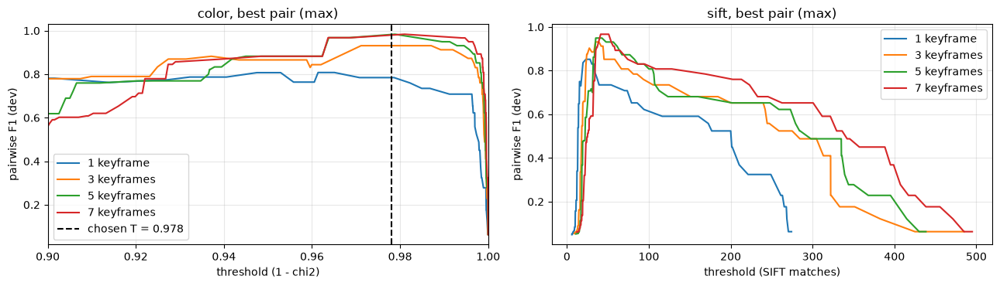

T = 0.958   P = 0.811   R = 0.968   F1 = 0.882
T = 0.962   P = 0.811   R = 0.968   F1 = 0.882
T = 0.966   P = 0.968   R = 0.968   F1 = 0.968
T = 0.970   P = 1.000   R = 0.968   F1 = 0.984
T = 0.974   P = 1.000   R = 0.968   F1 = 0.984
T = 0.978   P = 1.000   R = 0.968   F1 = 0.984
T = 0.982   P = 1.000   R = 0.968   F1 = 0.984
T = 0.986   P = 1.000   R = 0.968   F1 = 0.984
T = 0.990   P = 1.000   R = 0.903   F1 = 0.949
T = 0.994   P = 1.000   R = 0.871   F1 = 0.931
T = 0.998   P = 1.000   R = 0.742   F1 = 0.852


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, kind in zip(axes, ["color", "sift"]):
    for k in KEYFRAMES:
        res = scene_curves[k, kind, "max"]
        ax.plot([x[0] for x in res], [x[3] for x in res], label=f"{k} keyframe" + ("s" if k > 1 else ""))
    ax.set_xlabel("threshold (" + ("1 - chi2" if kind == "color" else "SIFT matches") + ")")
    ax.set_ylabel("pairwise F1 (dev)")
    ax.set_title(f"{kind}, best pair (max)")
    ax.grid(alpha=0.3)
axes[0].set_xlim(0.90, 1.0)
axes[0].axvline(recurring.T_SCENE, color="k", ls="--", label=f"chosen T = {recurring.T_SCENE}")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

# os valores a volta do threshold escolhido, para a configuracao do tp1.py
chosen = scene_sims[recurring.N_KEYFRAMES, recurring.SIM_KIND, recurring.COMBINE]
for T in np.arange(0.958, 0.999, 0.004):
    p, r, f1 = recurring.score_scenes(chosen, gts, T)
    print(f"T = {T:.3f}   P = {p:.3f}   R = {r:.3f}   F1 = {f1:.3f}")

With colour, 5 keyframes and `max`, the F1 is 0.984 for every threshold between 0.970 and 0.986. Below 0.970 two different scenes get linked (the precision drops), and above 0.986 shots of the same scene stop being linked (the recall drops). We take the middle of this range, T = 0.978 (`recurring.T_SCENE`), so that it is as far as possible from both edges. The range is narrow, only 0.016 wide, so this threshold may not work as well on the test videos. The SIFT curves have a sharp peak instead of a flat top, which is one more reason to prefer colour.

### 4.3 Similarity matrix and ground truth

The similarity matrix of the chosen method (colour, 5 keyframes, `max`) next to the ground truth matrix, where a pair is 1 when the two shots are in the same scene. The colour scale of the similarity starts at 0.9, otherwise everything above 0.9 looks the same.

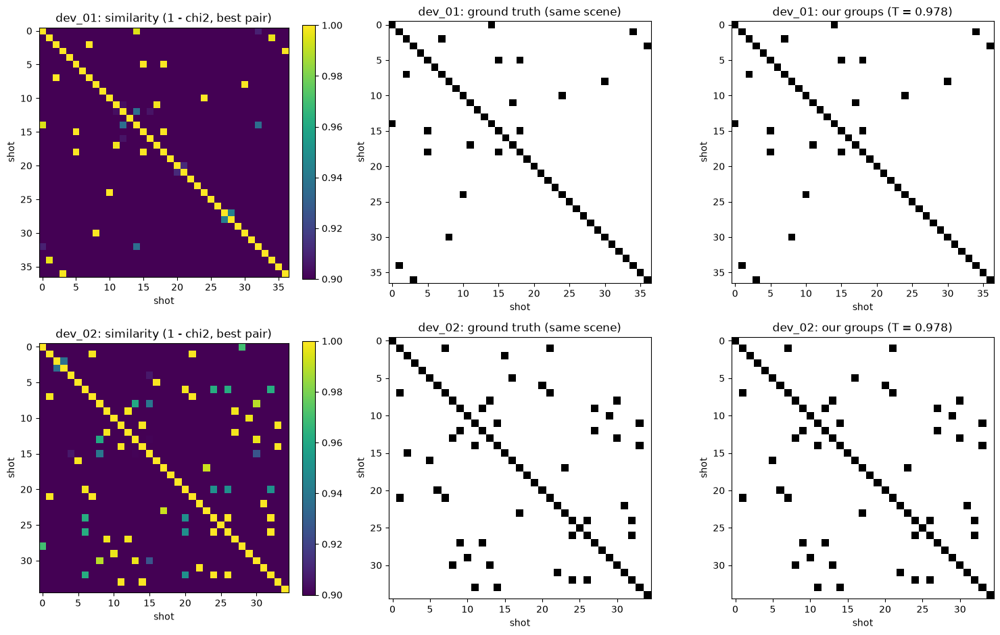

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for row, n in zip(axes, DEV):
    shots = gts[n]["shots"]
    sim = chosen[n].copy()
    np.fill_diagonal(sim, 1)   # a diagonal (um shot com ele proprio) fica a 0 na matriz, aqui so para o desenho
    scene = np.array([s["scene"] for s in shots])
    gt_matrix = (scene[:, None] == scene[None, :]).astype(float)
    labels = recurring.scene_labels(chosen[n], shots, recurring.T_SCENE)
    pred = np.array([labels[str(s["id"])] for s in shots])
    pred_matrix = (pred[:, None] == pred[None, :]).astype(float)

    im = row[0].imshow(sim, vmin=0.9, vmax=1, cmap="viridis")
    fig.colorbar(im, ax=row[0], fraction=0.046)
    row[0].set_title(f"{n}: similarity (1 - chi2, best pair)")
    row[1].imshow(gt_matrix, cmap="gray_r")
    row[1].set_title(f"{n}: ground truth (same scene)")
    row[2].imshow(pred_matrix, cmap="gray_r")
    row[2].set_title(f"{n}: our groups (T = {recurring.T_SCENE})")
    for ax in row:
        ax.set_xlabel("shot")
        ax.set_ylabel("shot")
fig.tight_layout()
plt.show()

On `dev_01` our groups are exactly the ground truth (F1 1.0). On `dev_02` there is one difference: the ground truth puts shots 2 and 15 in the same scene (the square at row 2, column 15) and we do not. In the similarity matrices almost every pair of shots is either very close to 1 or below 0.9, so most decisions are easy. The hard pairs are the few in between (the green and blue squares), for example shots 0 and 28 of `dev_02`, which are different scenes but reach 0.970, just under the threshold.

### 4.4 Storyboard

One keyframe per shot (the middle frame) of `dev_02`, in order, with a coloured border for every predicted scene that has more than one shot. Shots that end up alone have a grey border. The title gives the shot number and its ground truth scene.

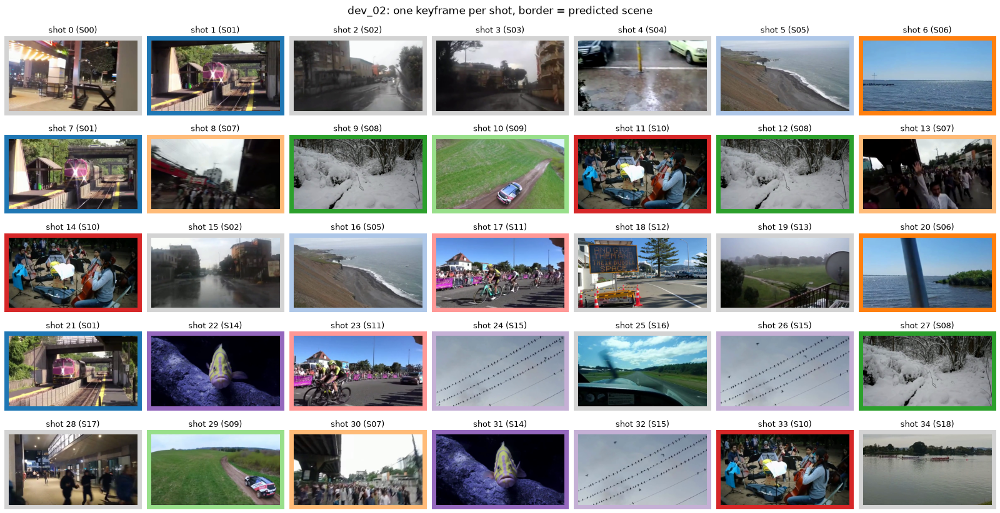

shots 8 and 13: colour similarity 0.960
shots 8 and 30: colour similarity 0.989
shots 13 and 30: colour similarity 0.997


In [26]:
def storyboard(n, labels, cols=7):
    # um keyframe por shot, com a borda da cor do grupo previsto (cinzento = shot sozinho no seu grupo)
    shots = gts[n]["shots"]
    values = list(labels.values())
    groups = sorted({l for l in values if values.count(l) > 1})
    colours = plt.cm.tab20.colors
    rows = int(np.ceil(len(shots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.3 * cols, 1.7 * rows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, shot in zip(axes.ravel(), shots):
        t = recurring.keyframes(shot, 1)[0]
        ax.imshow(cv2.cvtColor(frames[n][t], cv2.COLOR_BGR2RGB))
        label = labels[str(shot["id"])]
        colour = colours[groups.index(label) % 20] if label in groups else "lightgrey"
        # axis off tambem esconde a moldura, por isso voltamos a ligar so a moldura
        ax.axis("on")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color(colour)
            spine.set_linewidth(5)
        ax.set_title(f"shot {shot['id']} ({shot['scene']})", fontsize=9)
    fig.suptitle(f"{n}: one keyframe per shot, border = predicted scene")
    fig.tight_layout()
    return fig


labels_02 = recurring.scene_labels(chosen["dev_02"], gts["dev_02"]["shots"], recurring.T_SCENE)
storyboard("dev_02", labels_02);
plt.show()

# as semelhancas entre os tres shots da cena S07 (o sucesso discutido em baixo)
for a, b in [(8, 13), (8, 30), (13, 30)]:
    print(f"shots {a} and {b}: colour similarity {chosen['dev_02'][a, b]:.3f}")

**A success.** Scene S07 (shots 8, 13 and 30, light orange border) is a crowd under a bridge filmed from different positions, and the middle keyframes look quite different, with people waving in front of the camera in shot 13. Shots 8 and 13 only reach 0.960, below the threshold, but both are linked to shot 30 (0.989 and 0.997), so the connected components put the three shots together. The same happens with the train (S01), the orchestra (S10), the snow (S08) and the birds on the wires (S15): the colours of a scene stay very stable even when the content moves.

**A failure.** Shots 2 and 15 (grey border) are the same scene S02 in the ground truth, but each one ends up alone. Below are their 5 keyframes.

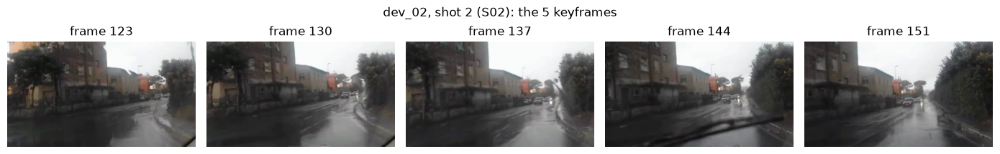

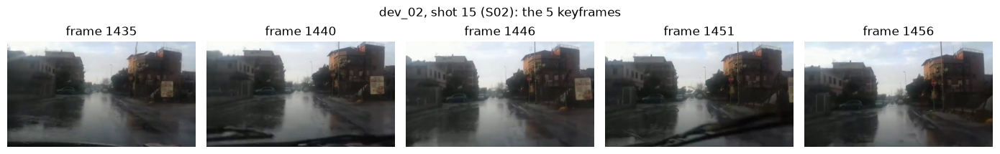

shots 2 and 15: colour similarity 0.819, best SIFT pair 9 matches


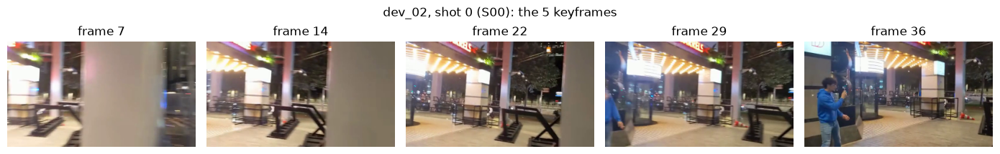

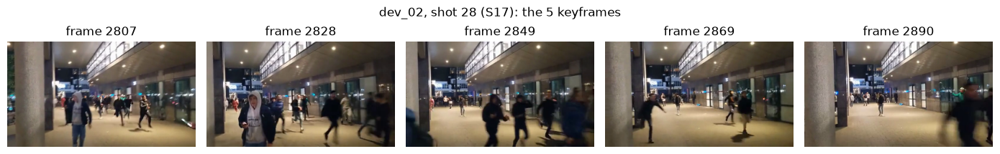

shots 0 and 28: colour similarity 0.9697 (threshold 0.978)


In [27]:
# o shot que falha: os shots 2 e 15 do dev_02 sao a mesma cena (S02) mas nao ficam ligados
shots_02 = gts["dev_02"]["shots"]
for i in [2, 15]:
    show_frames(frames["dev_02"], recurring.keyframes(shots_02[i], 5), f"dev_02, shot {i} ({shots_02[i]['scene']}): the 5 keyframes")
plt.show()
sift_2_15 = recurring.similarity_matrix(scene_feats[5]["dev_02"], "sift", "max")[2, 15]
print(f"shots 2 and 15: colour similarity {chosen['dev_02'][2, 15]:.3f}, best SIFT pair {sift_2_15:.0f} matches")

# e o par de cenas diferentes mais parecido, quase ligado por engano
for i in [0, 28]:
    show_frames(frames["dev_02"], recurring.keyframes(shots_02[i], 5), f"dev_02, shot {i} ({shots_02[i]['scene']}): the 5 keyframes")
plt.show()
print(f"shots 0 and 28: colour similarity {chosen['dev_02'][0, 28]:.4f} (threshold {recurring.T_SCENE})")

Both shots are filmed from a car driving in the rain, but the car has moved: shot 2 shows a dark street with trees and the wiper in front, and shot 15 a brighter stretch of road with a reddish building and more sky. No pair of keyframes shows the same view, so the colour similarity is only 0.819 and the best SIFT pair has 9 matches. Our similarities only see two different places, they cannot tell that it is the same take. Shot 2 is in fact closer to shot 3 (0.937), a different scene (S03) of another rainy street, which is the "two streets in the rain" case the assignment warns about. Here the threshold is high enough to keep them apart.

The near miss goes the other way. Shots 0 and 28 are different scenes (S00 and S17), but both are night views of a covered pedestrian area under warm artificial light, and their colour similarity is 0.9697, only 0.008 under the threshold. This is the main weakness of grouping by colour: it compares colours and not places, so two different scenes with the same lighting can be linked. A slightly lower threshold (0.966 in 4.2) already merges them.

## 5. Results (development and test)

The final configuration, as in `tp1.py`:
- **Cuts (Parts 1 and 2):** candidates are the peaks of the HSV histogram signal (16x2x1 bins, χ² distance) above `tp1.T_HIST = 0.0416`, with non-maximum suppression over 5 frames on each side. A candidate is rejected when frames t - 4 and t + 4 share at least 10 RANSAC inliers of SIFT matches.
- **Scenes (Part 3):** 5 keyframes per ground truth shot, colour similarity 1 - χ², the best pair of keyframes, and `grouping.group_shots` with T = 0.978.

All of this was chosen on the dev videos only, in sections 2 to 4. The test videos are evaluated here for the first time and nothing was changed after looking at them. As the assignment says, `tp1.py` is run first and writes the predictions to `../output`, and this cell only evaluates them. On our machine `tp1.py` takes about a minute for the four videos (it prints the time of each video).

In [28]:
# o tp1.py ja correu e escreveu as previsoes em ../output, aqui so as avaliamos
ALL = ["dev_01", "dev_02", "test_01", "test_02"]
TEST = ["test_01", "test_02"]
all_gts = {n: json.load(open(os.path.join(tp1.INPUT_DIR, n + ".json"))) for n in ALL}
preds = {n: json.load(open(os.path.join(tp1.OUTPUT_DIR, n + ".json"))) for n in ALL}
counts = {n: metrics.evaluate_video(all_gts[n], preds[n]) for n in ALL}
metrics.print_table([(n, counts[n]) for n in ALL]
                    + [("DEV", metrics.sum_counts([counts[n] for n in DEV])),
                       ("TEST", metrics.sum_counts([counts[n] for n in TEST]))])

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
dev_01      0.973  1.000   0.986       0/6    1.000    1.000     1.000
dev_02      0.944  1.000   0.971       1/6    1.000    0.952     0.976
test_01     0.679  0.973   0.800       0/6    1.000    0.929     0.963
test_02     0.953  1.000   0.976       1/6    1.000    0.600     0.750
DEV         0.959  1.000   0.979      1/12    1.000    0.968     0.984
TEST        0.802  0.987   0.885      1/12    1.000    0.792     0.884


**Cuts.** On the test videos the recall stays almost perfect (0.987, one cut missed) and only 1 of the 12 flashes gives a false cut, the same as on the dev videos, so the flash handling of Part 2 works on new videos too. `test_02` is as good as the dev videos (F1 0.976). The drop in precision comes from `test_01`: 17 false cuts, all inside the two fireworks shots of scene S14 (section 6.1). Without them the test precision would be close to the dev one.

**Scenes.** The scene precision is 1.0 on all four videos, so we never put two different scenes together. The recall drops on `test_02` (0.600): four pairs of shots of the same scene have a colour similarity between 0.946 and 0.974, just under our threshold of 0.978 (section 6.4). In section 4.2 we saw that the range of good thresholds on dev was narrow (0.970 to 0.986), and this is where it shows: a threshold a little lower would have linked most of these pairs, but on dev it would also have started linking different scenes.

## 6. Analysis and failure cases

**What works.** The HSV histogram without the brightness channel is a good cut detector: cuts change the colours, while flashes and auto exposure mostly change the brightness. Lowering its threshold and cleaning the candidates with non-maximum suppression and the SIFT verification gives an almost perfect recall with few false alarms. The verification is what removes most flashes: before and after a flash the frames show the same scene, so they share hundreds of RANSAC inliers. For scenes, comparing several keyframes per shot and keeping the best pair makes the grouping much more reliable than a single middle frame.

**Which signal is the most robust to motion and flashes.** From section 2.4, the colour histogram is the most robust single signal. With flashes it gives 3 false cuts out of 12, against 7 for the ECR and all 12 for the pixel difference. With camera motion the colours of the frame stay the same, so the histogram barely moves, while the ECR and the pixel difference react as soon as the image shifts. SIFT with RANSAC is the most robust check of all, because it looks for the same content under a camera motion, but it needs sharp and textured frames.

**What does not work.** The failures below have three causes: content whose colours change very fast without a cut (fireworks), frames without enough stable keypoints for SIFT (blur, sky, water, darkness), and a single global threshold for scenes when the colours of a scene change a bit between shots.

### 6.1 Failure 1: fireworks give false cuts

All the false cuts of `test_01` are listed below with their histogram value, the number of RANSAC inliers between frames t - 4 and t + 4, and the ground truth shot they fall in.

test_01: 17 false cuts
  frame 1683: histogram 0.114, 5 inliers, inside shot 18 (S14)
  frame 1689: histogram 0.116, 5 inliers, inside shot 18 (S14)
  frame 1695: histogram 0.087, 4 inliers, inside shot 18 (S14)
  frame 1702: histogram 0.185, 4 inliers, inside shot 18 (S14)
  frame 1718: histogram 0.128, 0 inliers, inside shot 18 (S14)
  frame 3082: histogram 0.153, 0 inliers, inside shot 32 (S14)
  frame 3097: histogram 0.120, 0 inliers, inside shot 32 (S14)
  frame 3103: histogram 0.087, 0 inliers, inside shot 32 (S14)
  frame 3113: histogram 0.201, 0 inliers, inside shot 32 (S14)
  frame 3121: histogram 0.166, 5 inliers, inside shot 32 (S14)
  frame 3128: histogram 0.085, 5 inliers, inside shot 32 (S14)
  frame 3135: histogram 0.114, 6 inliers, inside shot 32 (S14)
  frame 3151: histogram 0.152, 4 inliers, inside shot 32 (S14)
  frame 3170: histogram 0.105, 4 inliers, inside shot 32 (S14)
  frame 3176: histogram 0.116, 5 inliers, inside shot 32 (S14)
  frame 3182: histogram 0.087, 4

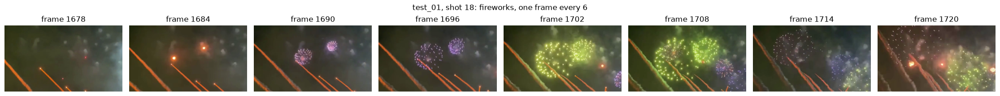

In [29]:
test01 = tp1.read_frames(os.path.join(tp1.INPUT_DIR, "test_01.mp4"))
gt01 = all_gts["test_01"]
d01 = signals.histogram_signal(test01)
cands01 = signals.local_maxima(d01, signals.detect_cuts(d01, tp1.T_HIST))
m01 = verify.candidate_matches(test01, cands01)          # os mesmos passos do tp1.process_video
cuts01 = [t["start"] for t in preds["test_01"]["transitions"]]
gt_cuts01 = [c["start"] for c in gt01["transitions"]]

fa01 = false_positives(cuts01, gt_cuts01)   # funcao da seccao 3.1
print(f"test_01: {len(fa01)} false cuts")
for t in fa01:
    shot = [s for s in gt01["shots"] if s["start"] <= t <= s["end"]][0]
    print(f"  frame {t}: histogram {d01[t]:.3f}, {m01.get(t)} inliers, inside shot {shot['id']} ({shot['scene']})")

show_frames(test01, range(1678, 1726, 6), "test_01, shot 18: fireworks, one frame every 6");

All 17 false cuts are inside the two fireworks shots of scene S14, about every 6 to 7 frames. Each new explosion fills the frame with a new colour (green, red, purple) on a dark sky, so the colour histogram changes as much as at a real cut, with values between 0.085 and 0.201, above our low threshold of 0.0416. The verification cannot save these candidates either. Frames t - 4 and t + 4 are dark, full of smoke and of light points that move and disappear, so SIFT finds at most 6 RANSAC inliers, below the minimum of 10. Both stages fail for the same reason: the content really changes very fast, only it is not a cut. There are no fireworks in the dev videos, so we could not see this when choosing the parameters. A possible fix would be to also ask for a change in the edges or in the structure of the image (for example the ECR, or matches on the background), since the buildings and the sky stay in place.

### 6.2 Failure 2: a real cut rejected by the verification

The only cut we miss on the test videos is a cut that the histogram finds without any problem but that the verification rejects.

missed cut at frame 1148: histogram 0.808, candidate: True, 11 RANSAC inliers


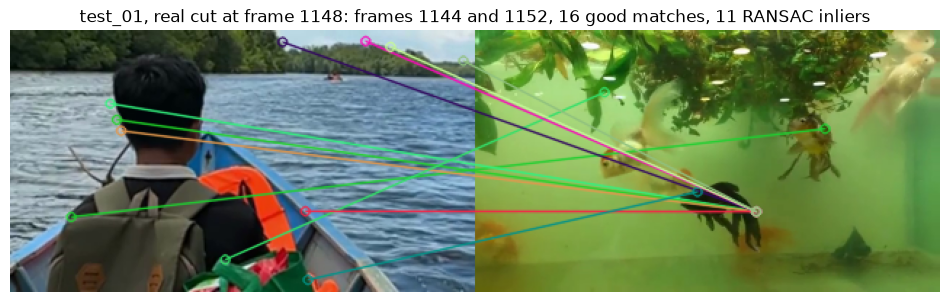

homography found by RANSAC:
[[ 4.5000e-01 -1.6500e+00  1.9418e+02]
 [ 2.9000e-01 -1.0600e+00  1.2421e+02]
 [ 0.0000e+00 -1.0000e-02  1.0000e+00]]


In [30]:
missed01 = [g for g in gt_cuts01 if all(abs(g - t) > metrics.TOLERANCE for t in cuts01)]
for t in missed01:
    print(f"missed cut at frame {t}: histogram {d01[t]:.3f}, candidate: {t in cands01}, {m01.get(t)} RANSAC inliers")

t = missed01[0]
g = verify.GAP
f1, f2 = test01[t - g], test01[t + g]
kp1, kp2, good = verify.sift_matches(f1, f2)
src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)   # o mesmo que o verify.count_matches
inliers = [m for m, keep in zip(good, mask.ravel()) if keep]
vis = cv2.drawMatches(f1, kp1, f2, kp2, inliers, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(12, 3.8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"test_01, real cut at frame {t}: frames {t - g} and {t + g}, {len(good)} good matches, {len(inliers)} RANSAC inliers")
plt.axis("off")
plt.show()
print("homography found by RANSAC:")
print(np.round(H, 2))

The cut from the boat to the fish tank at frame 1148 is obvious for the histogram (0.808, one of the highest values of the video). The two frames share almost nothing, but SIFT still finds 16 matches that pass the ratio test, between water ripples, leaves and fish. RANSAC then finds a homography that fits 11 of them, one more than our minimum of 10, so the candidate is rejected. The homography is nonsense: its first two columns rotate and flip the image, and some lines in the figure go from the boat to a single point of the fish. Two frames 8 frames apart in the same shot could never be related like this. RANSAC only checks that the points agree with some homography, not that the homography makes sense. A check on the homography (close to a small motion, positive determinant) or on the fraction of matches that are inliers would avoid this case.

### 6.3 Failure 3: fast motion and a flash on the sea

The two false cuts left on the dev videos that are not caused by a cut at all (section 3.5): frames t - 4, t - 1, t and t + 4 of each.

dev_01 frame 3342: histogram 0.069, 7 RANSAC inliers, no flash
dev_02 frame 1867: histogram 0.156, 0 RANSAC inliers, flash


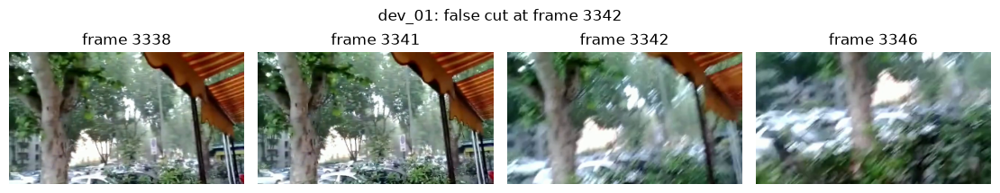

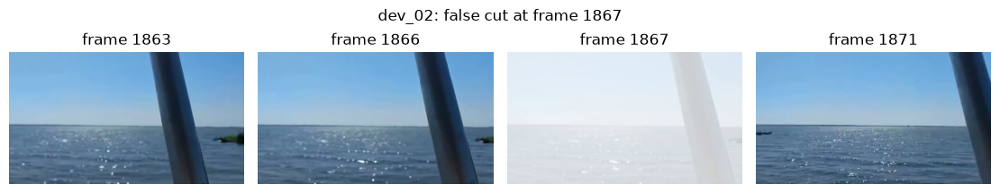

In [31]:
for n, t in [("dev_01", 3342), ("dev_02", 1867)]:
    inl = verify.count_matches(frames[n][t - verify.GAP], frames[n][t + verify.GAP])
    flash = near_flash(t, gts[n]["distractors"])
    print(f"{n} frame {t}: histogram {sig[n]['histogram'][t]:.3f}, {inl} RANSAC inliers" + (", flash" if flash else ", no flash"))
    show_frames(frames[n], [t - verify.GAP, t - 1, t, t + verify.GAP], f"{n}: false cut at frame {t}")
plt.show()

At frame 3342 of `dev_01` the camera turns quickly. The histogram value (0.069) is small, but it is a local maximum above our threshold. Frame 3346 is so blurred by the motion that SIFT finds only 7 inliers with frame 3338, and the candidate is kept as a cut. At frame 1867 of `dev_02` there is a flash on the sea. Frames 1863 and 1871 look almost the same to us, but the sky is flat, the sparkles on the water change every frame, and the only stable structure is the pole, so they share 0 inliers. In both cases the verification needs sharp and textured frames to recognise the same content.

### 6.4 Failure 4: scenes of `test_02` that are not grouped

The scene precision is 1.0 on every video, so we never put two different scenes together, but the recall of `test_02` is only 0.6. These are all the pairs of shots of `test_02` that are in the same scene in the ground truth and that we did not link directly.

shots 3 and 20 (S03): colour similarity 0.974, not grouped
shots 5 and 9 (S05): colour similarity 0.969, not grouped
shots 5 and 30 (S05): colour similarity 0.946, not grouped
shots 11 and 14 (S10): colour similarity 0.969, not grouped


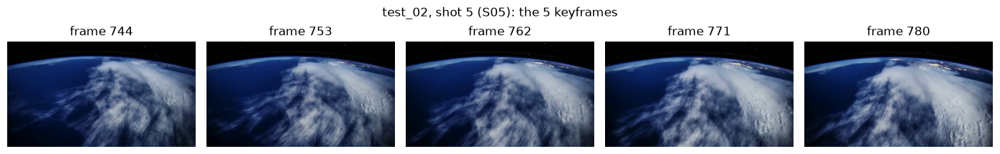

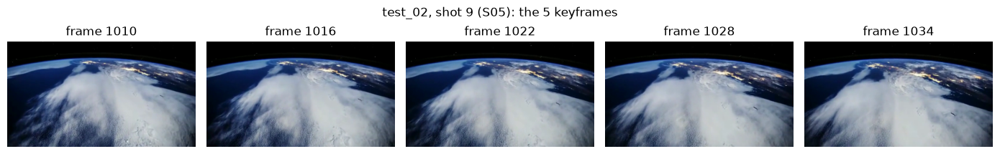

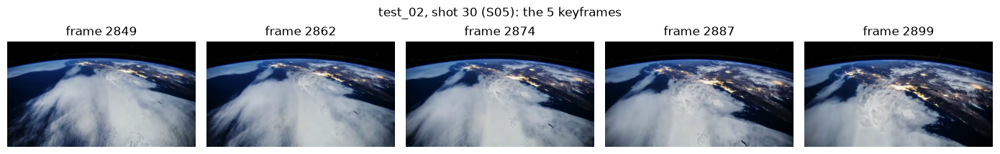

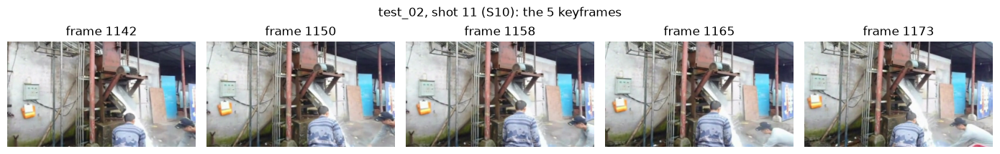

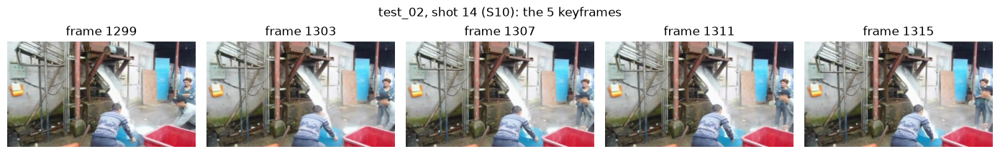

shots 5 and 9 (S05): 20 SIFT matches
shots 5 and 30 (S05): 10 SIFT matches
shots 11 and 14 (S10): 155 SIFT matches
shots 3 and 20 (S03): 71 SIFT matches


In [32]:
del test01   # liberta a memoria antes de ler o outro video
test02 = tp1.read_frames(os.path.join(tp1.INPUT_DIR, "test_02.mp4"))
shots02 = all_gts["test_02"]["shots"]
f02 = recurring.shot_features(test02, shots02, recurring.N_KEYFRAMES)
colour02 = recurring.similarity_matrix(f02, "color", "max")
labels02 = preds["test_02"]["scenes"]
for a in range(len(shots02)):
    for b in range(a + 1, len(shots02)):
        same_gt = shots02[a]["scene"] == shots02[b]["scene"]
        if same_gt and colour02[a, b] < recurring.T_SCENE:
            grouped = labels02[str(shots02[a]["id"])] == labels02[str(shots02[b]["id"])]
            print(f"shots {a} and {b} ({shots02[a]['scene']}): colour similarity {colour02[a, b]:.3f}"
                  + (", grouped through another shot" if grouped else ", not grouped"))

for i in [5, 9, 30, 11, 14]:
    show_frames(test02, recurring.keyframes(shots02[i], 5), f"test_02, shot {i} ({shots02[i]['scene']}): the 5 keyframes")
plt.show()

# os mesmos pares com SIFT (melhor par de keyframes), usados no texto e na seccao 8.2
sift02 = recurring.similarity_matrix(f02, "sift", "max")
for a, b in [(5, 9), (5, 30), (11, 14), (3, 20)]:
    print(f"shots {a} and {b} ({shots02[a]['scene']}): {sift02[a, b]:.0f} SIFT matches")

None of these pairs is linked, but the reason is always the same: the colours of the scene change a little from one shot to the other. Shots 5, 9 and 30 show the Earth seen from space while it turns. In shot 9 the night side with the city lights comes into view, so its colours are not the same as in shot 5 (0.969), and the colour similarity of shots 5 and 30 is only 0.946. Shots 11 and 14 show the same factory and the same workers from two slightly different positions, with a different amount of white water in the frame (0.969). These pairs are very easy for SIFT: shots 11 and 14 share 155 matches. This is the motivation for the extra of section 8.2. On the other side, the precision of 1.0 on every video shows that with this high threshold, colour alone never confused two different scenes.

## 7. Conclusion and self-evaluation

**Summary.** Our final detector finds the cuts with the colour histogram, a low threshold and non-maximum suppression, and removes the false alarms by checking with SIFT and RANSAC whether the frames before and after a candidate show the same content. On the test videos it reaches cut F1 0.885 (0.979 on dev), with 1 of 12 flashes giving a false cut. Scenes are found by comparing 5 keyframes per shot by colour and keeping the best pair, with pairwise F1 0.884 on test (0.984 on dev) and precision 1.0 on all videos. The whole program takes about a minute for the four videos, well under the 5 minutes allowed.

**Self-evaluation.** We think we did everything the assignment asks: the three signals with their PR curves and tables, the combination of signals, the SIFT verification with a study of the minimum number of matches, the four keyframe and similarity combinations for scenes, the similarity matrices, the storyboard, the final table and the failure analysis, with every choice made on the dev videos only. The weak points are the ones the test showed. The detector is not robust to content that changes colour very fast without a cut (fireworks), the verification can be fooled by a meaningless homography, and the scene threshold sits in a narrow range of good values, so it does not transfer perfectly to new videos. The extra of section 8.2 shows that adding SIFT to the scene similarity would help with the last point.

## 8. Extras

Things we did beyond the tasks:
- a study of the frame resolution (time, memory and F1) in section 2.0;
- non-maximum suppression of the cut candidates, which lets us use a much lower threshold (sections 3.4 and 3.5);
- RANSAC inliers instead of raw SIFT matches for the verification (section 3.3);
- the two experiments below: the sensitivity of the cut scores to the tolerance, and a scene similarity that combines colour and SIFT.

### 8.1 Sensitivity to the tolerance

The metric accepts a predicted cut up to 2 frames away from the ground truth. Here we score the final predictions with tolerances from 0 to 5 frames (`metrics.match_cuts` takes the tolerance as an argument).

In [33]:
print(f"{'tolerance':>9s} {'DEV P':>6s} {'DEV R':>6s} {'DEV F1':>6s} {'TEST P':>7s} {'TEST R':>7s} {'TEST F1':>7s}")
for tol in range(6):
    row = []
    for names in [DEV, TEST]:
        tp = fp = fn = 0
        for n in names:
            pred_cuts = [t["start"] for t in preds[n]["transitions"]]
            v_tp, v_fp, v_fn = metrics.match_cuts([c["start"] for c in all_gts[n]["transitions"]], pred_cuts, tol)
            tp += v_tp
            fp += v_fp
            fn += v_fn
        row += metrics.precision_recall_f1(tp, fp, fn)
    print(f"{tol:9d} {row[0]:6.3f} {row[1]:6.3f} {row[2]:6.3f} {row[3]:7.3f} {row[4]:7.3f} {row[5]:7.3f}")

tolerance  DEV P  DEV R DEV F1  TEST P  TEST R TEST F1
        0  0.959  1.000  0.979   0.802   0.987   0.885
        1  0.959  1.000  0.979   0.802   0.987   0.885
        2  0.959  1.000  0.979   0.802   0.987   0.885
        3  0.959  1.000  0.979   0.802   0.987   0.885
        4  0.959  1.000  0.979   0.802   0.987   0.885
        5  0.959  1.000  0.979   0.802   0.987   0.885


The scores do not change at all from tolerance 0 to 5: every cut we detect is on the exact frame of the ground truth cut, and every false cut is far from any real cut. This makes sense for hard cuts: the signal jumps exactly at the first frame of the new shot, and the non-maximum suppression keeps that frame. With gradual transitions such as fades, the tolerance would matter much more.

### 8.2 Combining colour and SIFT in one shot similarity

Colour never linked two different scenes on the dev videos, but it misses pairs of the same scene whose colours changed a bit. SIFT matches can catch some of these, because the same place keeps the same details. We link two shots when **either** the colour similarity passes `T_SCENE` **or** the best pair of keyframes has at least `T_SIFT` SIFT matches. To use `grouping.group_shots` with one matrix and one threshold, we divide each similarity by its own threshold and take the largest: two shots are linked when this value is at least 1.

The SIFT threshold is chosen on the dev videos. Since the extra links must be safe, we look at the largest number of matches between two shots of different scenes on dev and keep a margin above it.

In [34]:
colour_dev = scene_sims[5, "color", "max"]
sift_dev = scene_sims[5, "sift", "max"]
for n in DEV:
    scene = np.array([s["scene"] for s in gts[n]["shots"]])
    iu = np.triu_indices(len(scene), 1)
    different = (scene[:, None] != scene[None, :])[iu]
    print(f"{n}: at most {sift_dev[n][iu][different].max():.0f} SIFT matches between different scenes, "
          f"at least {sift_dev[n][iu][~different].min():.0f} inside the same scene")


def combined(colour, sift, t_sift):
    # cada semelhanca dividida pelo seu threshold: ligamos os dois shots se qualquer uma passar (valor >= 1)
    return np.maximum(colour / recurring.T_SCENE, sift / t_sift)


print()
print(f"{'T_SIFT':>6s} {'P':>6s} {'R':>6s} {'F1':>6s}   (dev)")
for t_sift in [20, 30, 40, 50, 60, 80, 100]:
    p, r, f1 = recurring.score_scenes({n: combined(colour_dev[n], sift_dev[n], t_sift) for n in DEV}, gts, 1.0)
    print(f"{t_sift:6d} {p:6.3f} {r:6.3f} {f1:6.3f}")

dev_01: at most 29 SIFT matches between different scenes, at least 10 inside the same scene
dev_02: at most 34 SIFT matches between different scenes, at least 9 inside the same scene

T_SIFT      P      R     F1   (dev)
    20  0.326  0.968  0.488
    30  0.588  0.968  0.732
    40  1.000  0.968  0.984
    50  1.000  0.968  0.984
    60  1.000  0.968  0.984
    80  1.000  0.968  0.984
   100  1.000  0.968  0.984


On dev, two different scenes never share more than 34 matches, and with `T_SIFT` from 40 up the scores are the same as colour alone. Below that the precision falls quickly. On the dev videos the combination neither helps nor hurts, because the only pair we miss on dev (shots 2 and 15 of `dev_02`, section 4.4) has only 9 SIFT matches. We take `T_SIFT = 50`, about 1.5 times the largest value seen between different scenes, to keep a safety margin.

In [35]:
T_SIFT = 50
# as features do test_01 ainda nao foram calculadas (na 6.1 so usamos os cortes), o test_02 ja esta em memoria
test_feats = {"test_02": f02}
del test02
test01 = tp1.read_frames(os.path.join(tp1.INPUT_DIR, "test_01.mp4"))
test_feats["test_01"] = recurring.shot_features(test01, all_gts["test_01"]["shots"], recurring.N_KEYFRAMES)
del test01

colour_all = dict(colour_dev)
sift_all = dict(sift_dev)
for n in TEST:
    colour_all[n] = recurring.similarity_matrix(test_feats[n], "color", "max")
    sift_all[n] = recurring.similarity_matrix(test_feats[n], "sift", "max")

print(f"{'':10s} {'colour only (tp1.py)':>22s} {'colour or SIFT >= ' + str(T_SIFT):>24s}")
for names, title in [([n], n) for n in ALL] + [(DEV, "DEV"), (TEST, "TEST")]:
    g = {n: all_gts[n] for n in names}
    a = recurring.score_scenes({n: colour_all[n] for n in names}, g, recurring.T_SCENE)
    b = recurring.score_scenes({n: combined(colour_all[n], sift_all[n], T_SIFT) for n in names}, g, 1.0)
    print(f"{title:10s}   P {a[0]:.3f} R {a[1]:.3f} F1 {a[2]:.3f}     P {b[0]:.3f} R {b[1]:.3f} F1 {b[2]:.3f}")

             colour only (tp1.py)     colour or SIFT >= 50
dev_01       P 1.000 R 1.000 F1 1.000     P 1.000 R 1.000 F1 1.000
dev_02       P 1.000 R 0.952 F1 0.976     P 1.000 R 0.952 F1 0.976
test_01      P 1.000 R 0.929 F1 0.963     P 1.000 R 0.929 F1 0.963
test_02      P 1.000 R 0.600 F1 0.750     P 1.000 R 0.800 F1 0.889
DEV          P 1.000 R 0.968 F1 0.984     P 1.000 R 0.968 F1 0.984
TEST         P 1.000 R 0.792 F1 0.884     P 1.000 R 0.875 F1 0.933


With the combination, the scene recall of `test_02` goes from 0.600 to 0.800 and the test F1 from 0.884 to 0.933, still with precision 1.0. The pairs of the market and of the factory (section 6.4) are now linked thanks to their SIFT matches. Shot 5 of the Earth is still alone, since it shares only 20 and 10 matches with the other two Earth shots. The scores on dev are exactly the same. Since the dev videos could not show this gain and the configuration of `tp1.py` was fixed before looking at the test videos, we did not change `tp1.py`. The results of section 5 are those of colour alone, and this combination is only reported as an extra.

## 9. Use of AI tools

We used Claude (Anthropic), through Claude Code, as an assistant during the project:
- to read the assignment, the lectures and the labs with us and explain how they relate to each part;
- to help write and simplify the code of `signals.py` and `recurring.py` and the changes to `tp1.py`, and to review the code of `verify.py`;
- to run the experiments on the dev videos and to look at the failure cases;
- to draft and correct parts of the text of this report.

All the code was read and checked by us, all the decisions were made by us on the dev videos, and every number in this report is produced by the code in this folder.